# 08 — Gradient Boosting

**Algorithm:** sklearn GradientBoostingClassifier  
**Features:** TF-IDF (5K) + TruncatedSVD (200 components) — dense features required  
Gradient Boosting fits trees on residuals/pseudo-residuals stage by stage. The deviance curves per iteration provide a clean convergence signal.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, evaluate_and_print, plot_confusion_matrix,
                   plot_roc_curve, plot_pr_curve, plot_learning_curve, get_dense_features)
from sklearn.metrics import accuracy_score, log_loss
BASE_DIR, FIGURES_DIR = setup_paths()

In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Train: 83,616  |  Test: 20,905


## Dense Feature Extraction (TF-IDF 5K + SVD-200)

In [3]:
X_tr_d, X_te_d, dense_idx = get_dense_features(X_train, X_test, max_features=5000, n_components=200, sample_size=20000)
y_tr_d = y_train[dense_idx] if dense_idx is not None else y_train
print(f'Dense features shape: Train={X_tr_d.shape}  Test={X_te_d.shape}')
print(f'Training samples used: {len(y_tr_d):,}')

Dense features shape: Train=(20000, 200)  Test=(20905, 200)
Training samples used: 20,000


## Model Training

In [4]:
from sklearn.ensemble import GradientBoostingClassifier
MODEL_NAME = 'Gradient Boosting'
model = GradientBoostingClassifier(n_estimators=100, random_state=42,
                                    learning_rate=0.1, max_depth=3,
                                    subsample=0.8)
t0 = time.time()
model.fit(X_tr_d, y_tr_d)
train_time = time.time() - t0
print(f'Training completed in {train_time:.2f}s')

Training completed in 103.60s


In [5]:
metrics, y_pred, y_prob = evaluate_and_print(model, X_te_d, y_test, MODEL_NAME, train_time)


  Gradient Boosting — Evaluation Results
  Accuracy          : 0.7771
  Precision         : 0.7792
  Recall            : 0.7771
  F1 Score          : 0.7711
  AUC-ROC           : 0.8619
  Train Time (s)    : 103.60s

              precision    recall  f1-score   support

    Fake (0)       0.79      0.61      0.69      8532
    Real (1)       0.77      0.89      0.83     12373

    accuracy                           0.78     20905
   macro avg       0.78      0.75      0.76     20905
weighted avg       0.78      0.78      0.77     20905



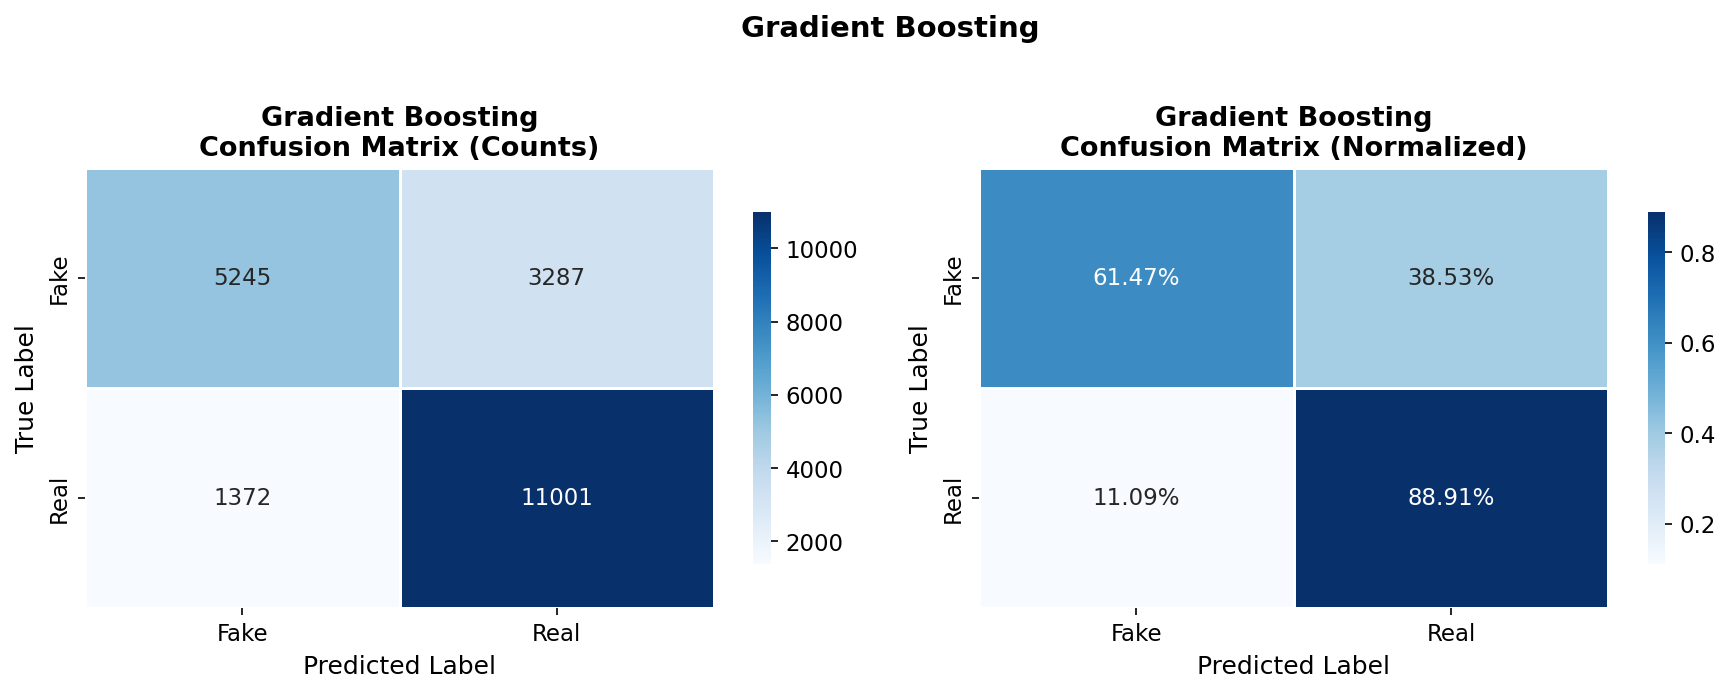

In [6]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

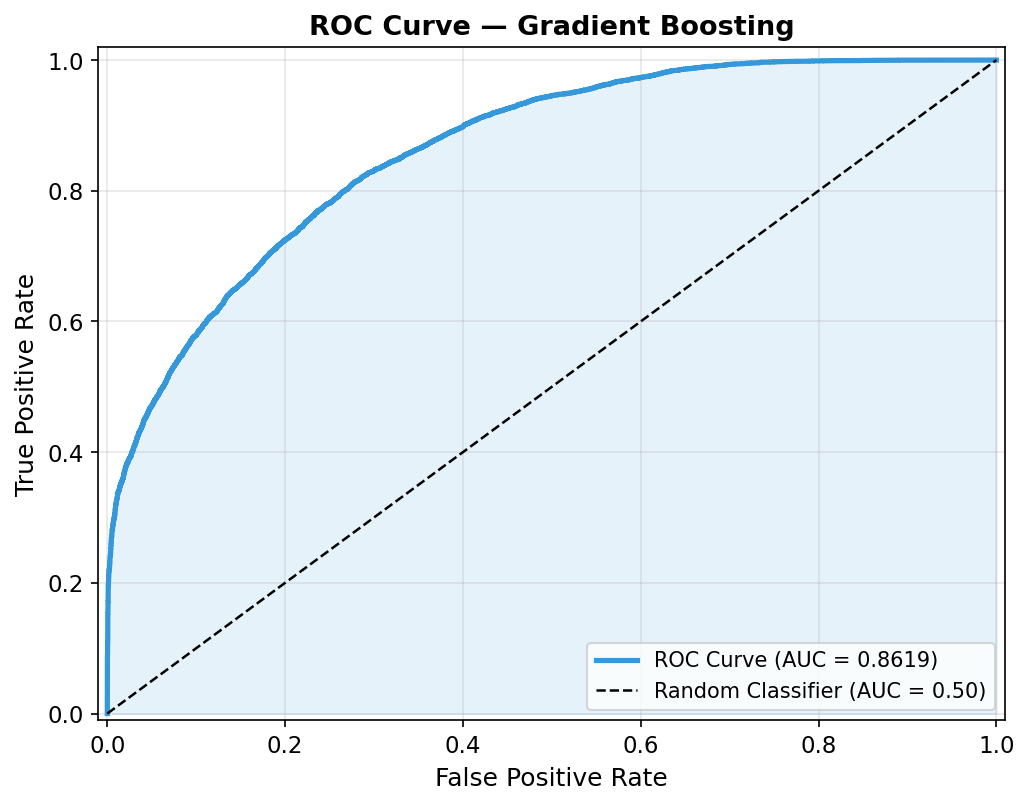

In [7]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

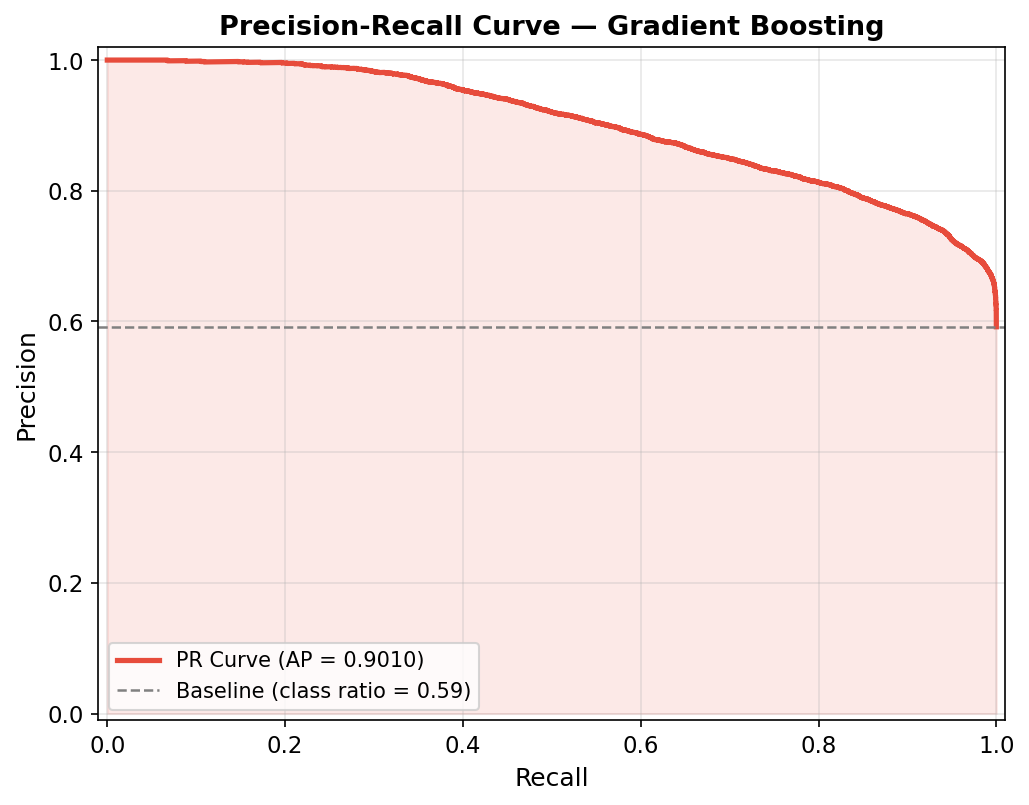

In [8]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Training Convergence: Staged Deviance per Iteration

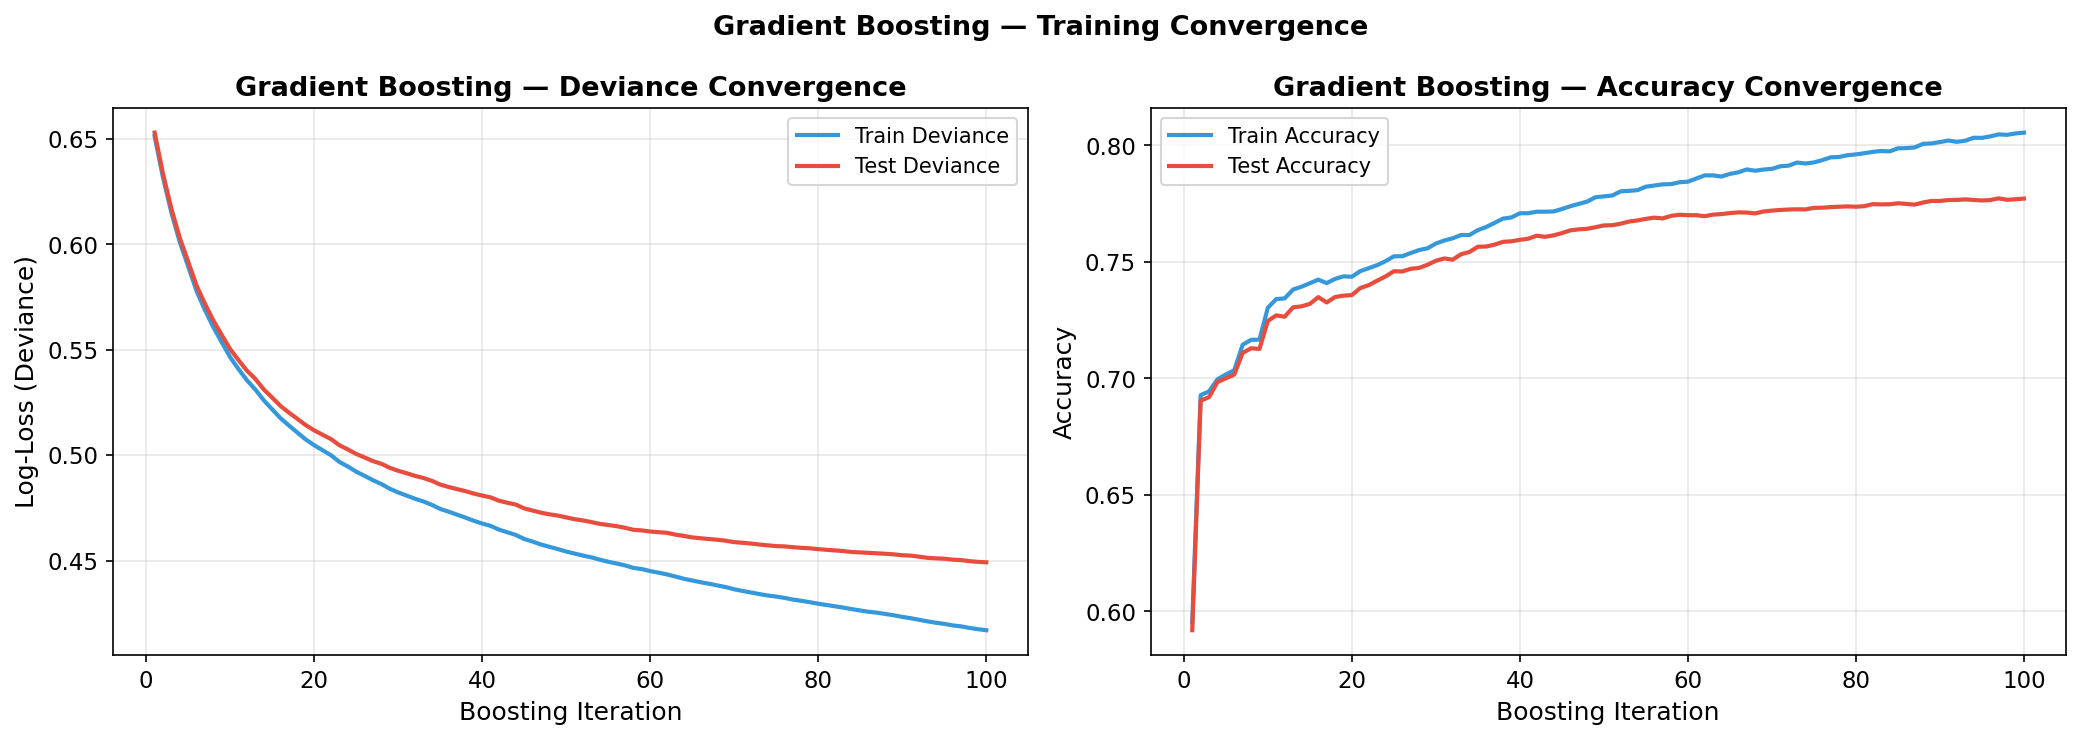

In [9]:
# Compute staged test deviance
staged_te_dev = []
for staged_pred in model.staged_predict_proba(X_te_d):
    staged_te_dev.append(log_loss(y_test, staged_pred))

staged_tr_dev = []
for staged_pred in model.staged_predict_proba(X_tr_d):
    staged_tr_dev.append(log_loss(y_tr_d, staged_pred))

iterations = np.arange(1, len(staged_tr_dev) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Deviance
axes[0].plot(iterations, staged_tr_dev, color='#3498db', lw=2, label='Train Deviance')
axes[0].plot(iterations, staged_te_dev, color='#e74c3c', lw=2, label='Test Deviance')
axes[0].set_xlabel('Boosting Iteration')
axes[0].set_ylabel('Log-Loss (Deviance)')
axes[0].set_title('Gradient Boosting — Deviance Convergence')
axes[0].legend(fontsize=10); axes[0].grid(alpha=0.3)

# Staged accuracy
staged_acc_tr = [accuracy_score(y_tr_d, p) for p in model.staged_predict(X_tr_d)]
staged_acc_te = [accuracy_score(y_test, p) for p in model.staged_predict(X_te_d)]
axes[1].plot(iterations, staged_acc_tr, color='#3498db', lw=2, label='Train Accuracy')
axes[1].plot(iterations, staged_acc_te, color='#e74c3c', lw=2, label='Test Accuracy')
axes[1].set_xlabel('Boosting Iteration')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Gradient Boosting — Accuracy Convergence')
axes[1].legend(fontsize=10); axes[1].grid(alpha=0.3)

plt.suptitle('Gradient Boosting — Training Convergence', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'gradient_boosting_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()

## Learning Curve

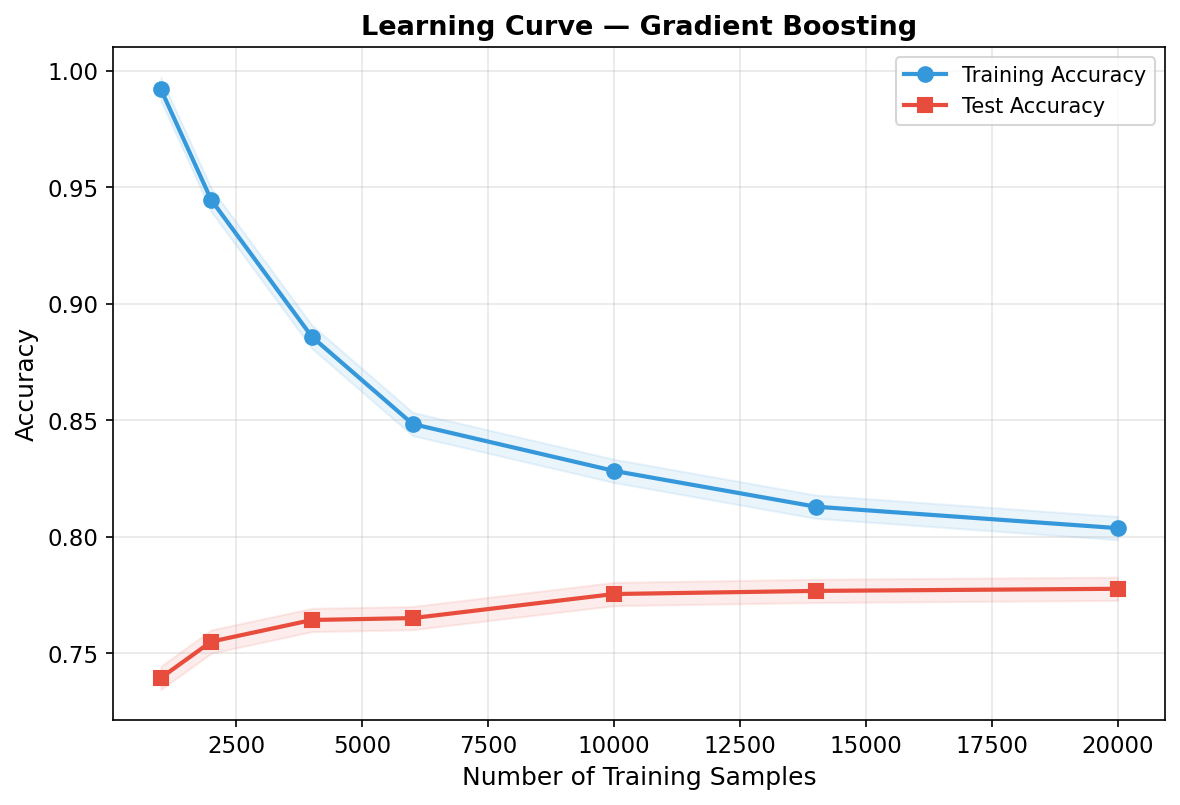

([1000, 2000, 4000, 6000, 10000, 14000, 20000],
 [0.992,
  0.9445,
  0.88575,
  0.8483333333333334,
  0.8282,
  0.8128571428571428,
  0.80365],
 [0.7393924898349677,
  0.7549390098062665,
  0.7642190863429802,
  0.7650322889260942,
  0.7753647452762497,
  0.7767041377660847,
  0.7776130112413299])

In [10]:
plot_learning_curve(model, X_tr_d, y_tr_d, X_te_d, y_test, MODEL_NAME, FIGURES_DIR)

## Feature Importances

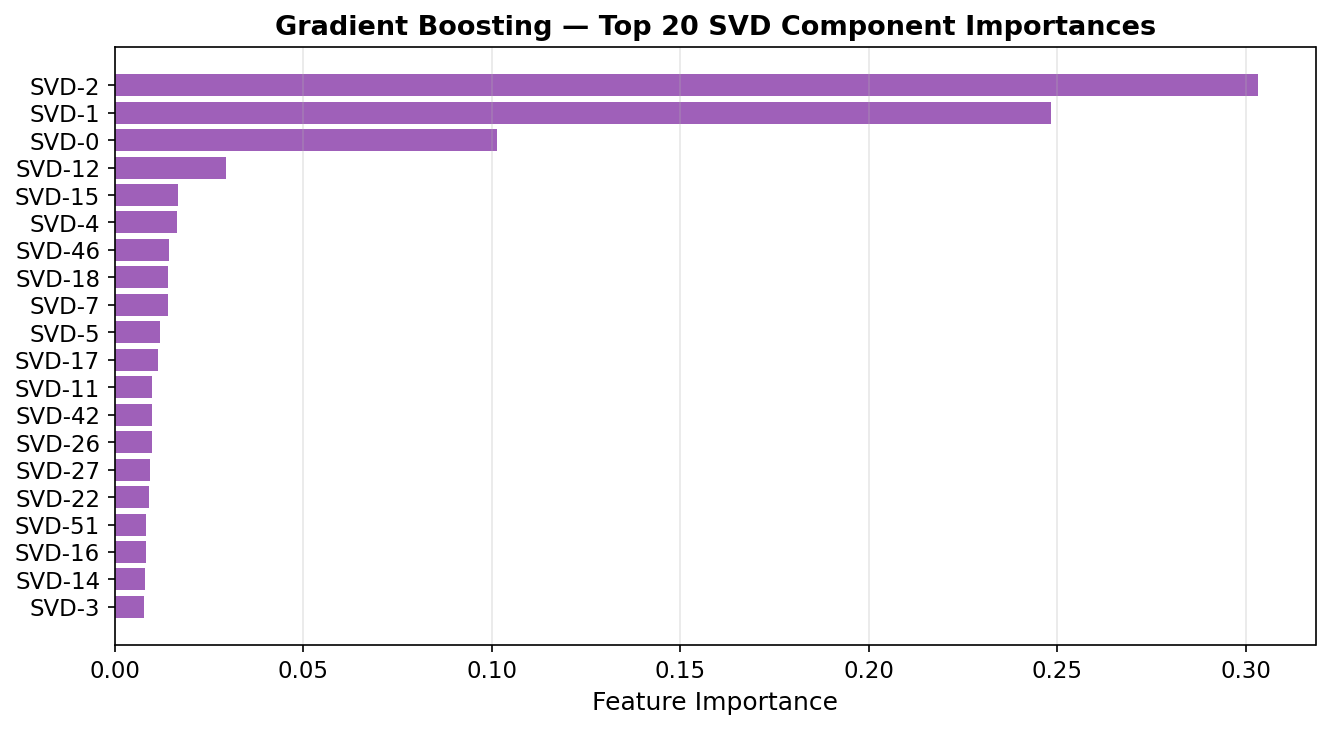

In [11]:
top_n = 20
fi = model.feature_importances_
top_idx = np.argsort(fi)[-top_n:][::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([f'SVD-{i}' for i in top_idx[::-1]], fi[top_idx[::-1]], color='#8e44ad', alpha=0.85)
ax.set_xlabel('Feature Importance')
ax.set_title('Gradient Boosting — Top 20 SVD Component Importances')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'gradient_boosting_feature_importance.png'), dpi=150, bbox_inches='tight')
plt.show()